<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS10/LAB-01/PEMMES1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Lab 1
Klasifikasi Bunga Iris dengan Perceptron
#Deskripsi
Pada praktikum ini, Anda diminta untuk melakukan klasifikasi bunga iris dengan menggunakan model Perceptron. Anda dapat menggunakan dataset iris pada praktikum sebelumnya.

Untuk menambah pemahaman Anda terkait dengan model Perceptron, pada praktikum ini Anda akan membuat model Perceptron tanpa menggunakan library.

#Langkah 1 - Import Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#Langkah 2 - Load Data dan Visualisasi

In [5]:
df = pd.read_csv('Iris.csv', header=None)
print(df.head())
print(df[4].unique())

    0              1             2              3             4            5
0  Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
1   1            5.1           3.5            1.4           0.2  Iris-setosa
2   2            4.9           3.0            1.4           0.2  Iris-setosa
3   3            4.7           3.2            1.3           0.2  Iris-setosa
4   4            4.6           3.1            1.5           0.2  Iris-setosa
['PetalWidthCm' '0.2' '0.4' '0.3' '0.1' '0.5' '0.6' '1.4' '1.5' '1.3'
 '1.6' '1.0' '1.1' '1.8' '1.2' '1.7' '2.5' '1.9' '2.1' '2.2' '2.0' '2.4'
 '2.3']


50 50 50


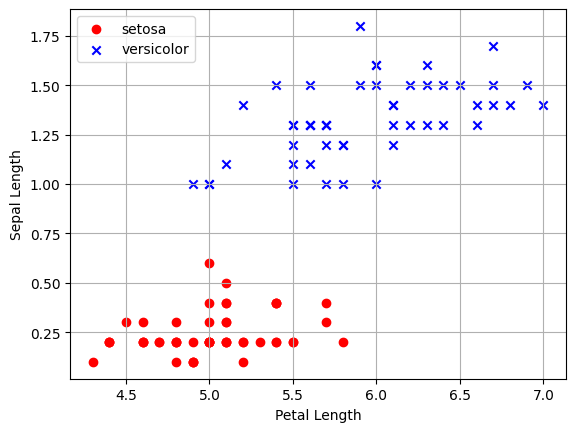

In [12]:
df = pd.read_csv('Iris.csv')
df = df.drop(columns=[c for c in df.columns if str(c).lower() == 'id'])
df.columns = range(df.shape[1])
df[4] = 'Iris-' + df[4].astype(str).str.replace('Iris-', '', regex=False)

setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']
virginica = df[df[4] == 'Iris-virginica']
print(len(setosa), len(versicolor), len(virginica))

a, b = 0, 3
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Petal Length')
plt.ylabel('Sepal Length')
plt.legend(loc='upper left')
plt.grid()
plt.show()

#Langkah 3 - Membuat Kelas Perceptron

In [13]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

#Langkah 4 - Pilih Data dan Encoding Label

In [14]:
y = df.iloc[0:100, 4].values # pilih 100 data awal
y = np.where(y == 'Iris-setosa', -1, 1) # ganti coding label
X = df.iloc[0:100, [0, 3]].values # slice data latih

#Langkah 5 - Fitting Model

In [15]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

#Langkah 6 - Visualisasi Nilai Error Per Epoch

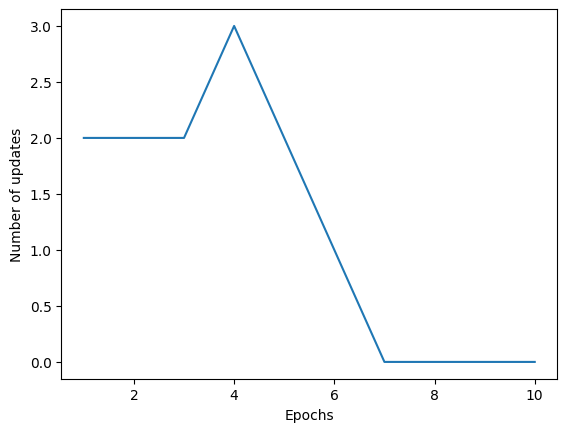

In [16]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

#Langkah 7 - Visualisasi Decision Boundary

In [18]:
# buat fungsi untuk plot decision region

from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(),xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)

/tmp/ipykernel_1325/3924338356.py:27: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)


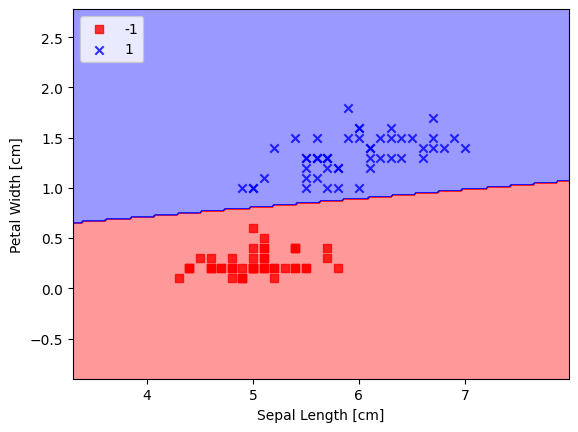

In [19]:
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('Sepal Length [cm]')
plt.ylabel('Petal Width [cm]')
plt.legend(loc='upper left')
plt.show()